In [41]:
%pip install matplotlib numpy scipy pillow opencv-python

   ---------------------------------------- 0.0/44.0 MB ? eta -:--:--
   -- ------------------------------------- 2.9/44.0 MB 21.3 MB/s eta 0:00:02
   ------- -------------------------------- 7.9/44.0 MB 22.4 MB/s eta 0:00:02
   ---------- ----------------------------- 12.1/44.0 MB 22.2 MB/s eta 0:00:02
   -------------- ------------------------- 16.0/44.0 MB 21.3 MB/s eta 0:00:02
   ------------------ --------------------- 20.4/44.0 MB 21.2 MB/s eta 0:00:02
   ---------------------- ----------------- 25.2/44.0 MB 21.2 MB/s eta 0:00:01
   -------------------------- ------------- 29.6/44.0 MB 21.4 MB/s eta 0:00:01
   ------------------------------ --------- 34.1/44.0 MB 21.4 MB/s eta 0:00:01
   ----------------------------------- ---- 38.5/44.0 MB 21.6 MB/s eta 0:00:01
   ---------------------------------------  43.3/44.0 MB 21.5 MB/s eta 0:00:01
   ---------------------------------------- 44.0/44.0 MB 20.6 MB/s  0:00:02
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [42]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
from scipy.ndimage import zoom
import scipy.signal as sp
import scipy.fft as fft
from PIL import Image, ImageFilter
import cv2

In [37]:
def Decimate(img, factor, method, filter=False):
    """
    Decimate an image by a given factor using a specified method.

    Parameters:
    img (numpy.ndarray): Input image to be decimated.
    factor (int): Factor by which to decimate the image.
    method (str): Method to use for decimation ('nearest', 'bilinear', 'bicubic').

    Returns:
    numpy.ndarray: Decimated image.
    """

    if filter:
        # Apply a low-pass filter before decimation to avoid aliasing
        F = np.fft.fft2(img)
        F_shifted = np.fft.fftshift(F)
        for i in range(F_shifted.shape[0]):
            for j in range(F_shifted.shape[1]):
                if abs(i - F_shifted.shape[0] // 2) > F_shifted.shape[0] // (2 * factor) or abs(j - F_shifted.shape[1] // 2) > F_shifted.shape[1] // (2 * factor):
                    F_shifted[i, j] = 0
        img = np.fft.ifft2(np.fft.ifftshift(F_shifted)).real

    if method == 'nearest':
        return img[::factor, ::factor]
    elif method == 'bilinear':
        return zoom(img, (1/factor, 1/factor), order=1)
    elif method == 'bicubic':
        return zoom(img, (1/factor, 1/factor), order=3)
    else:
        raise ValueError("Method must be 'nearest', 'bilinear', or 'bicubic'.")

In [21]:
def ShowImage(img, title='Image', cmap="gray", vmin=0, vmax=255):
    """
    Display an image using matplotlib.

    Parameters:
    img (numpy.ndarray): Image to be displayed.
    title (str): Title of the image display window.
    """
    plt.figure()
    plt.imshow(img, cmap=cmap, vmin=vmin, vmax=vmax)
    plt.title(title)
    plt.axis('off')
    plt.show()

## Ejercicio 1

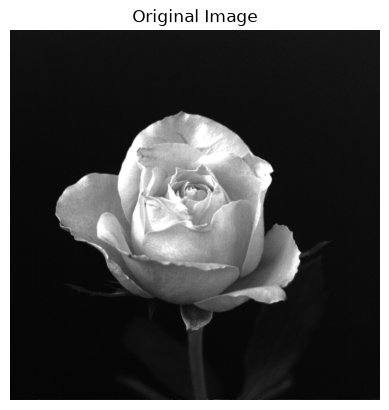

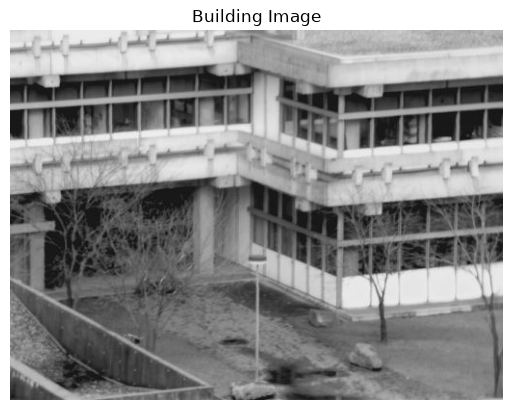

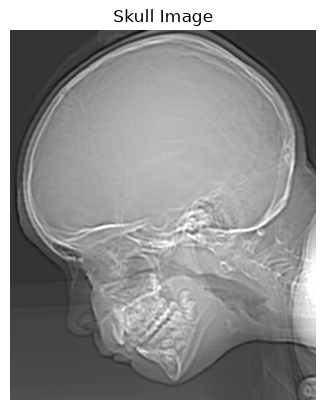

In [22]:
rose = mpimg.imread('ej1-rose.tif')
building = mpimg.imread('ej1-building.jpg')
skull = mpimg.imread('ej1-skull.tif')

ShowImage(rose, 'Original Image')
ShowImage(building, 'Building Image')
ShowImage(skull, 'Skull Image')

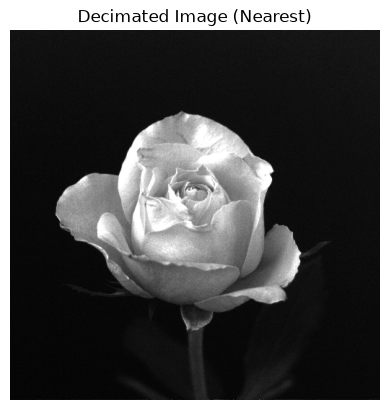

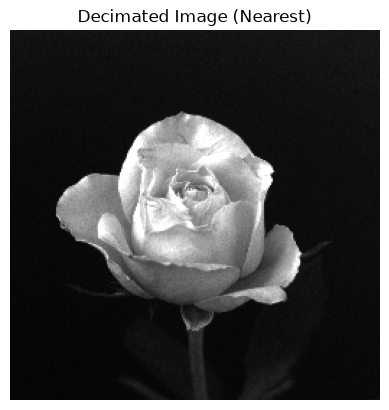

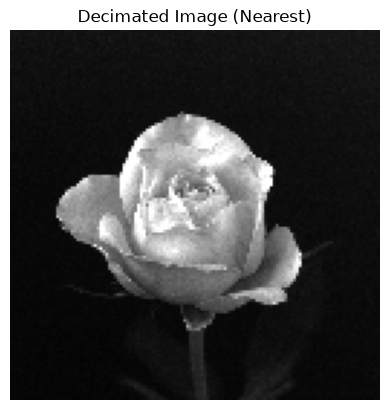

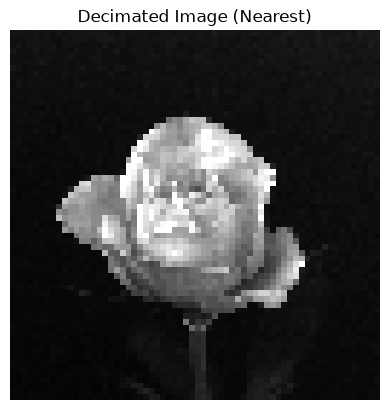

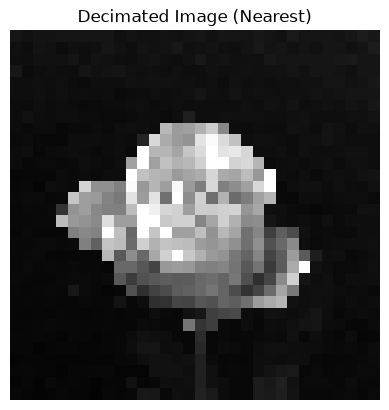

In [23]:
rose1 = Decimate(rose, 2, 'nearest')
ShowImage(rose1, 'Decimated Image (Nearest)')

rose2 = Decimate(rose1, 2, 'nearest')
ShowImage(rose2, 'Decimated Image (Nearest)')

rose3 = Decimate(rose2, 2, 'nearest')
ShowImage(rose3, 'Decimated Image (Nearest)')

rose4 = Decimate(rose3, 2, 'nearest')
ShowImage(rose4, 'Decimated Image (Nearest)')

rose5 = Decimate(rose4, 2, 'nearest')
ShowImage(rose5, 'Decimated Image (Nearest)')

#TODO: Ver de mantener el tamaño original

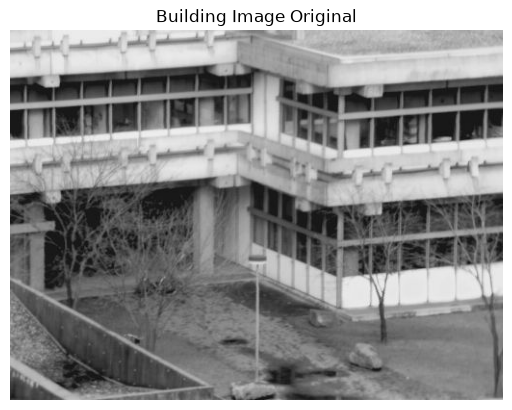

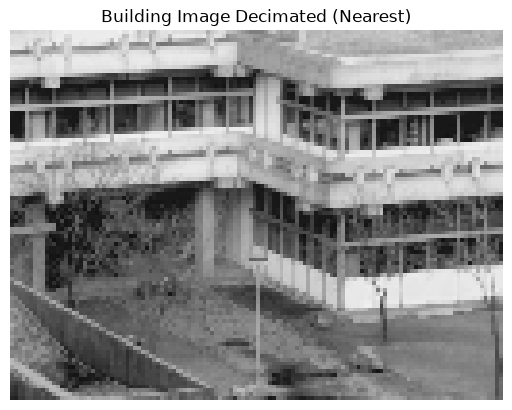

In [24]:
ShowImage(building, 'Building Image Original')
ShowImage(Decimate(building, 4, 'nearest'), 'Building Image Decimated (Nearest)')

In [25]:
def ReduceCuantization(img, factor):
    """
    Reduce the quantization of an image by a given factor.

    Parameters:
    img (numpy.ndarray): Input image to be quantized.
    factor (int): Factor by which to reduce the quantization.

    Returns:
    numpy.ndarray: Quantized image.
    """
    return (img // factor) * factor

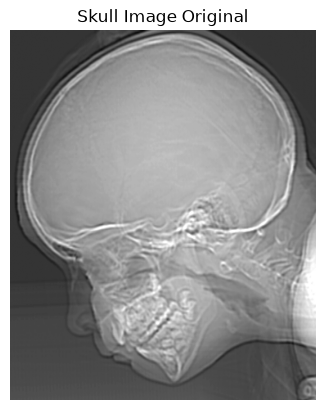

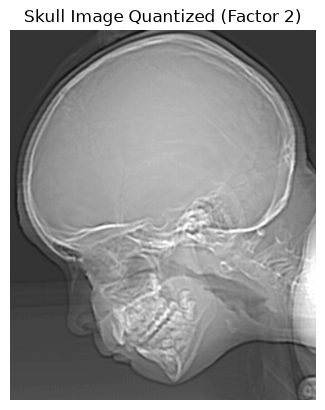

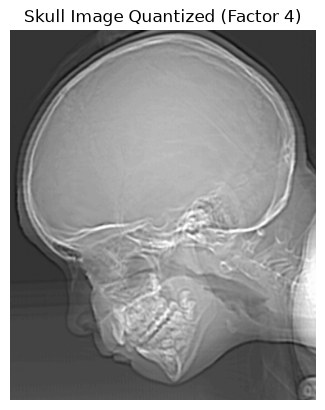

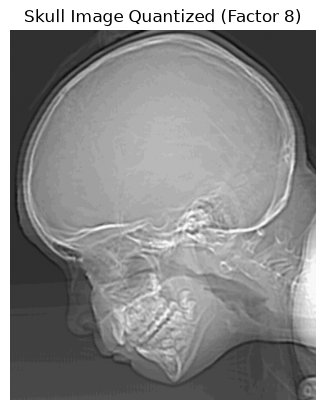

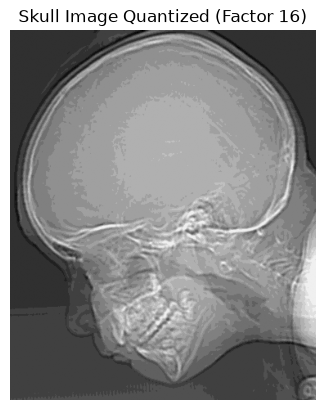

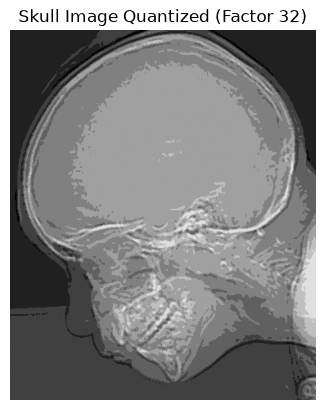

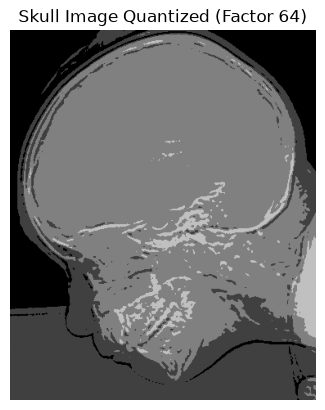

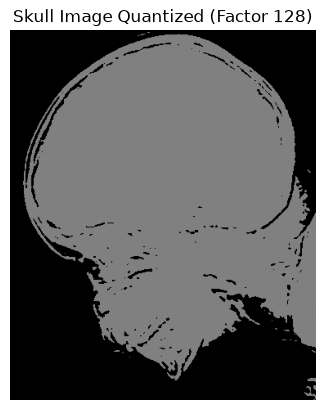

In [26]:
ShowImage(skull, 'Skull Image Original')
skull1 = ReduceCuantization(skull, 2)
ShowImage(skull1, 'Skull Image Quantized (Factor 2)')
skull2 = ReduceCuantization(skull, 4)
ShowImage(skull2, 'Skull Image Quantized (Factor 4)')
skull3 = ReduceCuantization(skull, 8)
ShowImage(skull3, 'Skull Image Quantized (Factor 8)')
skull4 = ReduceCuantization(skull, 16)
ShowImage(skull4, 'Skull Image Quantized (Factor 16)')
skull5 = ReduceCuantization(skull, 32)
ShowImage(skull5, 'Skull Image Quantized (Factor 32)')
skull6 = ReduceCuantization(skull, 64)
ShowImage(skull6, 'Skull Image Quantized (Factor 64)')
skull7 = ReduceCuantization(skull, 128)
ShowImage(skull7, 'Skull Image Quantized (Factor 128)')

## Ejercicio 2

In [27]:
def ApplyFilter(img, filter):
    return sp.convolve2d(img, filter, mode='same')

### Ex1

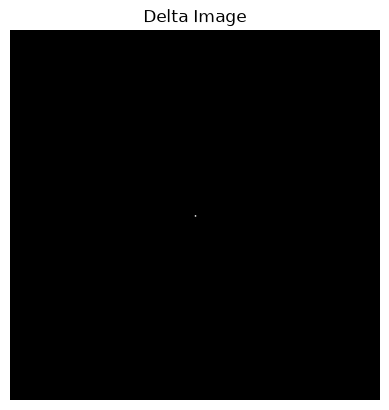

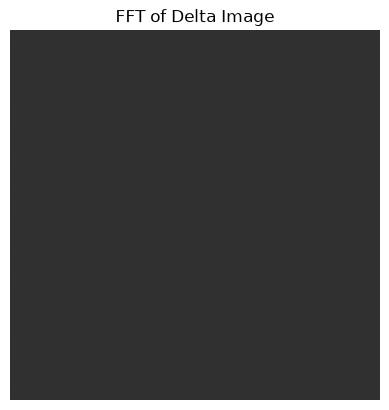

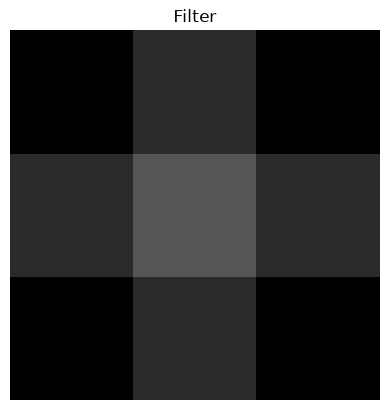

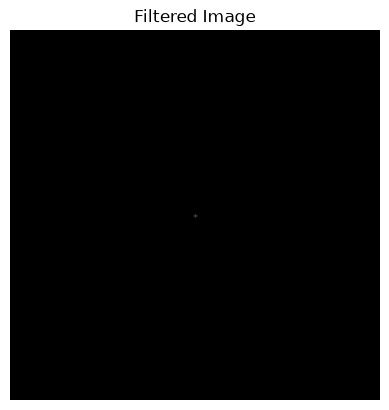

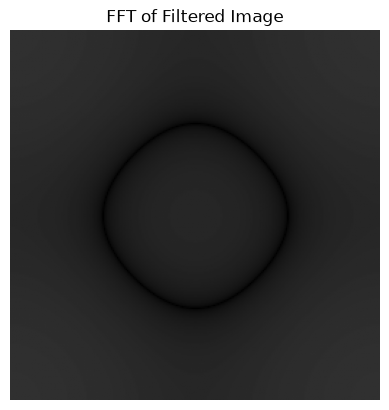

In [28]:
N = 256
img = np.zeros((N, N))
img[N//2, N//2] = 256  # Delta at 0, 0
ShowImage(img, 'Delta Image')

ShowImage(20*np.log10(np.abs(fft.fft2(img))), 'FFT of Delta Image')

# Filter
filter = np.array([[0, 1/6, 0], [1/6, 1/3, 1/6], [0, 1/6, 0]])
ShowImage(filter, 'Filter', vmax=1)

filtered_img = ApplyFilter(img, filter)
ShowImage(filtered_img, 'Filtered Image')
ShowImage(20*np.log10(1 + np.abs(fft.fft2(filtered_img))), 'FFT of Filtered Image')

### Ex2.m

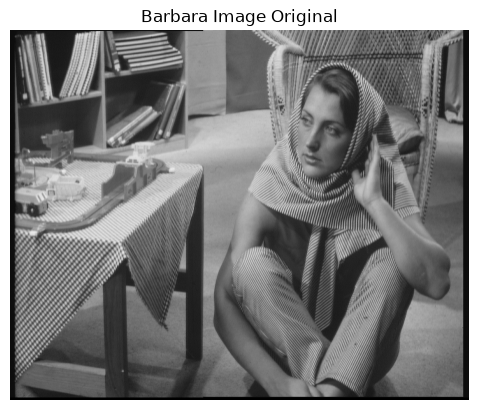

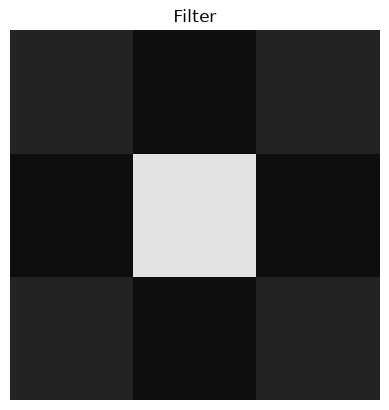

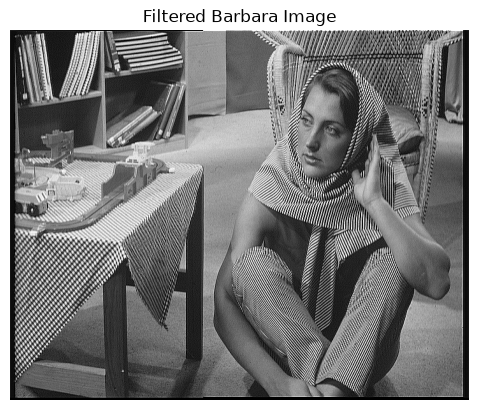

In [29]:
barbara = mpimg.imread('barbara.gif')
barbara = barbara[:, :, 0]
ShowImage(barbara, 'Barbara Image Original')

filter = np.array([
    [-0.1667, -0.6667, -0.1667],
    [-0.6667,  4.3333, -0.6667],
    [-0.1667, -0.6667, -0.1667]
])

ShowImage(filter, 'Filter', vmin=-1, vmax=5)

filtered_barbara = ApplyFilter(barbara, filter)
ShowImage(filtered_barbara, 'Filtered Barbara Image')

In [35]:
def interpolacion_bilineal(img_small, new_w, new_h):
    w, h = img_small.shape

    result = np.zeros((new_w, new_h))

    scale_x = w / new_w
    scale_y = h / new_h

    for x in range(new_w):
        for y in range(new_h):

            # Coordenadas correspondientes en imagen pequeña
            src_x = x * scale_x
            src_y = y * scale_y

            x0 = int(np.floor(src_x))
            y0 = int(np.floor(src_y))

            Q00 = img_small[x0,                 y0]
            Q10 = img_small[x0,                 min(y0 + 1, h - 1)]
            Q01 = img_small[min(x0 + 1, w - 1), y0]
            Q11 = img_small[min(x0 + 1, w - 1), min(y0 + 1, h - 1)]

            dx = src_x - x0
            dy = src_y - y0

            result[x, y] = (
                  Q11 * dx       * dy
                + Q01 * dx       * (1 - dy)
                + Q10 * (1 - dx) * dy
                + Q00 * (1 - dx) * (1 - dy)
            )

    return result

### Viasampling.m

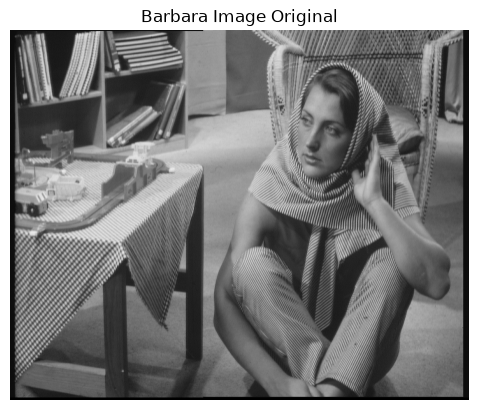

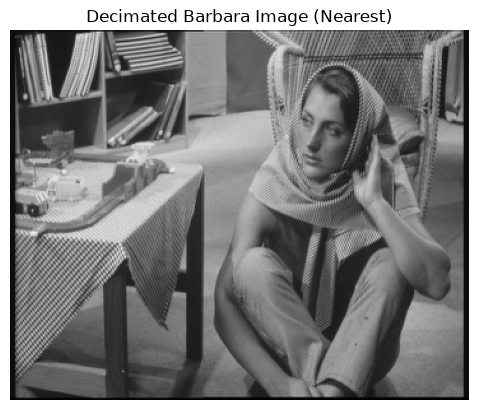

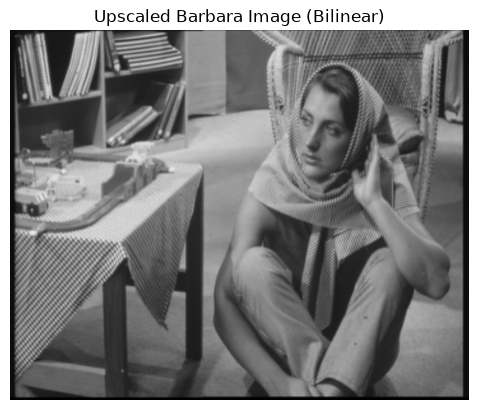

In [38]:
ShowImage(barbara, 'Barbara Image Original')
barbara_decimated = Decimate(barbara, 2, 'nearest', filter=True)
ShowImage(barbara_decimated, 'Decimated Barbara Image (Nearest)')
barbara_upscaled = interpolacion_bilineal(barbara_decimated, barbara.shape[0] * 2, barbara.shape[1] * 2)
ShowImage(barbara_upscaled, 'Upscaled Barbara Image (Bilinear)')

### Spec.m

Min: 0.0
Max: 100.0


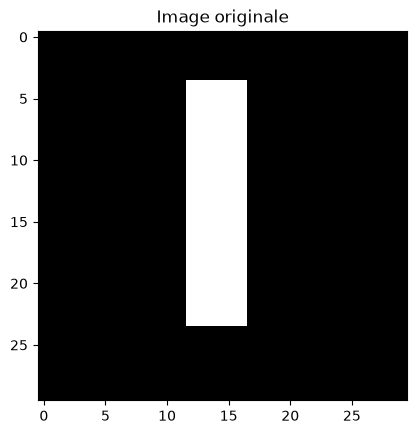

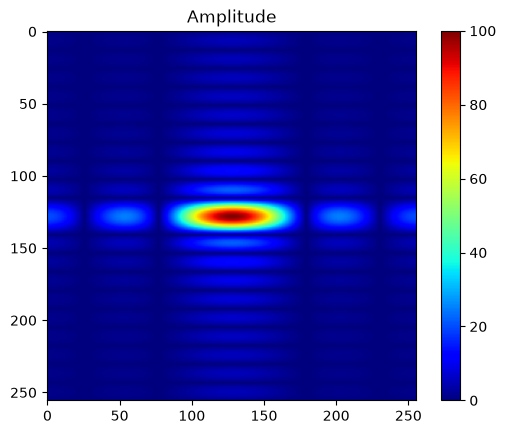

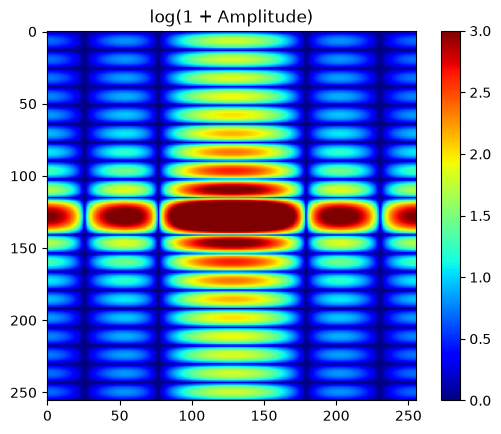

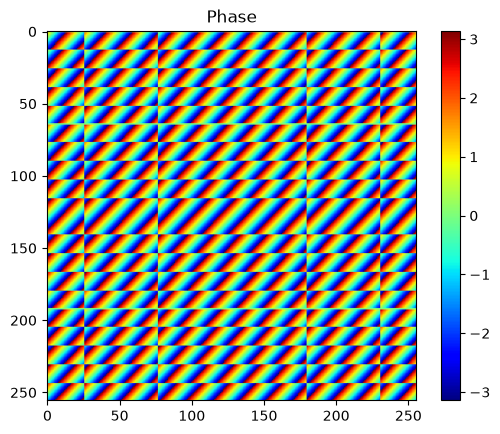

In [34]:
# Prepare image
f = np.zeros((30, 30))
# En Python, l'indexation commence à 0 et la borne de fin est exclue (5:24 en Matlab -> 4:24)
f[4:24, 12:17] = 1

plt.figure()
plt.imshow(f, cmap="gray")
plt.title("Image originale")

# Compute Fourier Transform
F = np.fft.fft2(f, s=(256, 256))
F = np.fft.fftshift(F)  # Center FFT

# Measure the minimum and maximum value of the transform amplitude
abs_F = np.abs(F)
print("Min:", np.min(abs_F))  # ~0
print("Max:", np.max(abs_F))  # ~100

plt.figure()
plt.imshow(abs_F, cmap="jet", vmin=0, vmax=100)
plt.colorbar()
plt.title("Amplitude")

plt.figure()
plt.imshow(np.log(1 + abs_F), cmap="jet", vmin=0, vmax=3)
plt.colorbar()
plt.title("log(1 + Amplitude)")

plt.figure()
plt.imshow(np.angle(F), cmap="jet", vmin=-np.pi, vmax=np.pi)
plt.colorbar()
plt.title("Phase")

plt.show()

### Image_aliasing_new.m

In [43]:
f = cv2.imread("barbara.gif", cv2.IMREAD_GRAYSCALE)

xsize, ysize = f.shape

fps = 10
fourcc = cv2.VideoWriter_fourcc(*'XVID')

mov_pics = cv2.VideoWriter("aliasing_pics.avi", fourcc, fps, (xsize, ysize), isColor=False)
mov_specs = cv2.VideoWriter("aliasing_specs.avi", fourcc, fps, (xsize, ysize), isColor=False)

for xshrink in range(0, 601, 5):

    desired_xsize = xsize - xshrink

    if desired_xsize <= 0:
        break

    desired_ysize = int(round(ysize * desired_xsize / xsize))
    f2 = cv2.resize(f, (desired_xsize, desired_ysize), interpolation=cv2.INTER_LINEAR)
    current_xsize, current_ysize = f2.shape
    f3 = cv2.resize(f2, (xsize, ysize), interpolation=cv2.INTER_LINEAR)

    F = np.fft.fft2(f3)
    F_shift = np.fft.fftshift(F)

    Fd = np.log(1 + np.abs(F_shift))

    Fd_norm = 255 * Fd / np.max(Fd)
    Fd_norm = Fd_norm.astype(np.uint8)

    print(xshrink)

    mov_pics.write(f3)
    mov_specs.write(Fd_norm)

mov_pics.release()
mov_specs.release()

0
5
10
15
20
25
30
35
40
45
50
55
60
65
70
75
80
85
90
95
100
105
110
115
120
125
130
135
140
145
150
155
160
165
170
175
180
185
190
195
200
205
210
215
220
225
230
235
240
245
250
255
260
265
270
275
280
285
290
295
300
305
310
315
320
325
330
335
340
345
350
355
360
365
370
375
380
385
390
395
400
405
410
415
420
425
430
435
440
445
450
455
460
465
470
475
480
485
490
495
500
505
510
515
520
525
530
535
540
545
550
555
560
565
570
575


Loading images...
Computing correlation...


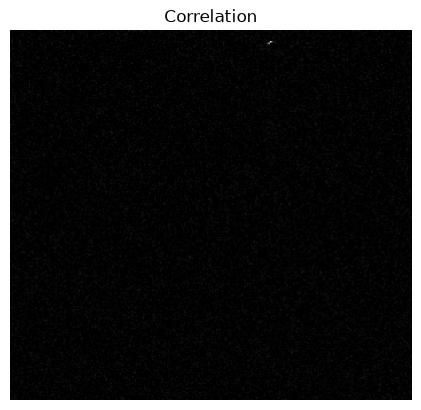

Max correlation at: (194, 8)


In [ ]:
def corr(I_a, I_b):
    """
    Computes the correlation between two images I_a and I_b.
    """

    I_a = np.mean(I_a, axis=2)  
    I_b = np.mean(I_b, axis=2) 

    F_a = np.fft.fftshift(np.fft.fft2(I_a))
    F_b = np.fft.fftshift(np.fft.fft2(I_b))

    cross_power_spectrum = (F_a * np.conj(F_b)) / (np.abs(F_a * np.conj(F_b)) + 1e-10)

    correlation = np.fft.ifft2(cross_power_spectrum).real

    return correlation

path_a = "dog1ss.jpg"
path_b = "dog2ss.jpg"

print("Loading images...")
I_a = mpimg.imread(path_a, format='jpg')
I_b = mpimg.imread(path_b, format='jpg')

I_a = I_a.astype(np.float32)
I_b = I_b.astype(np.float32)

print("Computing correlation...")
C = corr(I_a, I_b)

ShowImage(C, 'Correlation', vmin=0, vmax=0.1)

column, row = np.unravel_index(np.argmax(C), C.shape)
print(f"Max correlation at: ({row}, {column})")



En este fragmento de código se calcula la imagen de correlación (secuencia de correlación en 2D) utilizando calculando el PSD en 2D

Según como se posicionen las imágenes, el resultado en X o en Y pueden ser los complementos de los valores obtenidos. La imagen original es de 300 x 300, por lo que el desplazamiento en X puede ser de 300 - 194 = 106 y el de Y  de 300 - 8 = 292 pixeles.